## **Programming For Data Analytics (ST1510) CA2**

**Names:** Zacus Hee **(2508472)** & Cayden Sim **(2501893)**

**Class:** DAAA/FT/1B/01




---
## Dataset Links:
- Dataset 1 and 2 were taken from the Brightspace datasets under the file 'CA2 Datasets'


# **Main Research Question:**
## "Which university degrees in Singapore provide the best career value in terms of employment security, salary competitiveness, and long-term earning potential (2013-2022)?"



### **Sub-Questions:**
- Which degrees consistently achieve employment rates above 90% across multiple years?

- How do graduate starting salaries compare to Singapore's median income by industry?

- Which fields show the strongest salary growth trajectory over time?

- What is the "career value score" combining employment rate, salary competitiveness, and stability?

---
# **Step 1:** Importing Necessary Libraries


In [455]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

- **Libraries Imported:**
  - pandas
  - numpy
  - matplotlib
  - seaborn
- **pandas** and **numpy** are used for data analysis.
- **matplotlib** and **seaborn** are used for data visualization.

---
# **Step 2:** Loading Datasets from File Explorer

In [456]:


# cayden file:
grad_survey1 = pd.read_csv("C:/Users/nedya/OneDrive/Desktop/PDAS/CA2/CA2 Datasets/(1) graduate employment survey modified.csv")
grad_survey2 = pd.read_csv("C:/Users/nedya/OneDrive/Desktop/PDAS/CA2/CA2 Datasets/(2) graduate employment survey modified .csv")
# df3 = pd.read_excel("C:/Users/nedya/OneDrive/Desktop/PDAS/CA2/CA2 Datasets/LFR2023_SectionD.xlsx")




---
# **Step 3:** Exploratory Data Analysis **(EDA)**


In this section, the basic information and statistics of each dataset will be displayed.
- We aim to:
    - Identify any null values in columns/empty columns.
    - Identify if any duplicates are present.

This helps us to identify what we need to clean in the preprocessing section.

In [457]:
# Display basic info
print(f"Dataset 1 shape: {grad_survey1.shape}")
print(f"Dataset 2 shape: {grad_survey2.shape}")

Dataset 1 shape: (5135, 5)
Dataset 2 shape: (5135, 48)


- The code prints the shape of each dataset, so that we know how many rows and columns we are working with, and how many rows / columns we should expect to have after cleaning.

In [458]:
# Show first few rows
display(grad_survey1.head())
display(grad_survey2.head())

,year,university,school,degree,Key
0,2013,Nanyang Technological University,College of Business (Nanyang Business School),Accountancy and Business,1
1,2013,Nanyang Technological University,College of Business (Nanyang Business School),Accountancy (3-yr direct Honours Programme),2
2,2013,Nanyang Technological University,College of Business (Nanyang Business School),Business (3-yr direct Honours Programme),3
3,2013,Nanyang Technological University,College of Business (Nanyang Business School),Business and Computing,4
4,2013,Nanyang Technological University,College of Engineering,Aerospace Engineering,5


,employment_rate_overall,employment_rate_ft_perm,basic_monthly_mean,basic_monthly_median,gross_monthly_mean,gross_monthly_median,gross_mthly_25_percentile,gross_mthly_75_percentile,gross_monthly_mean.1,gross_monthly_median.1,...,Unnamed: 38,Unnamed: 39,Unnamed: 40,Unnamed: 41,Unnamed: 42,Unnamed: 43,Unnamed: 44,Unnamed: 45,Unnamed: 46,Key
0,97.4,96.1,3701,3200,3727,3350,2900,4000,3727,3350,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1
1,97.1,95.7,2850,2700,2938,2700,2700,2900,2938,2700,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2
2,90.9,85.7,3053,3000,3214,3000,2700,3500,3214,3000,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3
3,87.5,87.5,3557,3400,3615,3400,3000,4100,3615,3400,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4
4,95.3,95.3,3494,3500,3536,3500,3100,3816,3536,3500,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5


- Using the **`'.head()'`** function, the first 5 rows of each dataset is printed.

In [459]:
# Display dataset informatio
grad_survey1.info()
grad_survey2.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5135 entries, 0 to 5134
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   year        5135 non-null   object
 1   university  5135 non-null   object
 2   school      5135 non-null   object
 3   degree      5135 non-null   object
 4   Key         5135 non-null   int64 
dtypes: int64(1), object(4)
memory usage: 200.7+ KB
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5135 entries, 0 to 5134
Data columns (total 48 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   employment_rate_overall      5027 non-null   object 
 1   employment_rate_ft_perm      5027 non-null   object 
 2   basic_monthly_mean           5027 non-null   object 
 3   basic_monthly_median         5027 non-null   object 
 4   gross_monthly_mean           5027 non-null   object 
 5   gross_monthly_median         5027 non-null  

After that, we display the information of each dataset.
- The output shows:
    - The number of non-null values in each row.
    - The data types of the column.


- What can be observed:
    - The columns of dataset 1 has a non-null count of 5135.
        - Since the number of rows in dataset 1 is 5135, it means that the columns of dataset 1 are all filled.
    - The main columns of dataset 2 (excluding 'key' column), has a non-null count of 5027:
        - With the total number of rows in dataset 2 being 5135, it indicates that there are missing values in the columns of dataest 2. This will be confirmed in the following steps.

In [460]:
# Checking for duplicates
print(f"Number of duplicates in Dataset 1: {grad_survey1.duplicated().sum()}")
print(f"Number of duplicates in Dataset 2: {grad_survey2.duplicated().sum()}")

Number of duplicates in Dataset 1: 0
Number of duplicates in Dataset 2: 0


Check for any duplicates in each dataset.
- Using **`'.duplicated().sum()'`**, we have identified the number of duplicated values in each dataset. 
- The **`'.sum()'`** function acts as a counter to count the number of duplicated values.

In [461]:
print(f"Number of null values in df1: \n{grad_survey1.isnull().sum()}")
print(f"Number of null values in df2: \n{grad_survey2.isnull().sum()}")

Number of null values in df1: 
year          0
university    0
school        0
degree        0
Key           0
dtype: int64
Number of null values in df2: 
employment_rate_overall         108
employment_rate_ft_perm         108
basic_monthly_mean              108
basic_monthly_median            108
gross_monthly_mean              108
gross_monthly_median            108
gross_mthly_25_percentile       108
gross_mthly_75_percentile       108
gross_monthly_mean.1            108
gross_monthly_median.1          108
gross_mthly_25_percentile.1     108
gross_mthly_75_percentile.1     108
Unnamed: 12                    5135
Unnamed: 13                    5135
Unnamed: 14                    5135
Unnamed: 15                    5135
Unnamed: 16                    5135
Unnamed: 17                    5135
Unnamed: 18                    5135
Unnamed: 19                    5135
Unnamed: 20                    5135
Unnamed: 21                    5135
Unnamed: 22                    5135
Unnamed: 23      

The code checks for any null values in the dataset.
- From the output, it can be seen that several columns have 108 missing values, while the unnamed columns have **5135**, which is the size of the entire dataset, indicating that all the unnamed columns are empty. 
- Drop empty columns and fill in the missing data in the other columns in the next section: **Preprocessing** 

---
# **Step 4:** Preprocessing
- Data cleaning will be conducted here.
- Includes:
  - Filling of missing data
  - Dropping missing/empty rows
  - Addition of new columns
  - Conversion of string to numbers

### **Merging the 2 Datasets:**

In [462]:
# 1. Merge the two graduate datasets
merged_grad = pd.merge(grad_survey1, grad_survey2, on='Key', how='inner')

print(f"Merged dataset shape: {merged_grad.shape}")

Merged dataset shape: (5135, 52)


- Merged the 2 datasets using pandas' **`'.merge()'`** function, passing the 2 datasets in as the arguments, and merging based on the common column **`'key'`**.

- Printing the shape of the merged dataset now shows 5135 rows and 52 columns.
    - 52 columns although dataset 1 has 5 columns and dataset 2 has 48 columns because both datasets contain key. Since we are merging based on 'key', the merged DataFrame would only have 1 'key' column.

---
### **Handling Missing Values**

In [463]:
# 2. Handle missing values
# Check missing values
print("\nMissing values before cleaning:")
print(merged_grad.isnull().sum())

# Drop rows where employment rate is missing
merged_grad = merged_grad.dropna(subset=['employment_rate_overall'])




Missing values before cleaning:
year                              0
university                        0
school                            0
degree                            0
Key                               0
employment_rate_overall         108
employment_rate_ft_perm         108
basic_monthly_mean              108
basic_monthly_median            108
gross_monthly_mean              108
gross_monthly_median            108
gross_mthly_25_percentile       108
gross_mthly_75_percentile       108
gross_monthly_mean.1            108
gross_monthly_median.1          108
gross_mthly_25_percentile.1     108
gross_mthly_75_percentile.1     108
Unnamed: 12                    5135
Unnamed: 13                    5135
Unnamed: 14                    5135
Unnamed: 15                    5135
Unnamed: 16                    5135
Unnamed: 17                    5135
Unnamed: 18                    5135
Unnamed: 19                    5135
Unnamed: 20                    5135
Unnamed: 21                    

- Print the number of null value in each column.

- Columns from dataset 1 (year to Key), have a count of 0, indicating that those columns are full with no empty cells.

- Main columns from dataset 2 (employment_rate_overall to gross_mnthly_75_percentile.1), have a count of 108, indicating that there are 108 empty cells in the dataset.

- There are 35 Unamed columns and they have a count of 5135, meaning that the whole column of each unnamed column is empty.
    - Dropping them is recommended.

Next: 
- Drop the rows in **`'employment_rate_overall'`** column where its value is **`NaN`** and ignore all other **`NaN`** values in other columns.
- In other words, only dropping rows where the **`'employment_rate_overall'`** column contains **`NaN`** no matter how many other NaN values there are in other columns


---
### **Dropping 'Unnamed' Columns:**

In [464]:
print(f"Before Dropping Unnamed Columns: Merged Dataset looks like this: {merged_grad.shape}")

# Drop all unnamed columns
merged_grad = merged_grad.dropna(axis=1, how='all')
print(f"After Dropping Unnamed Columns: Merged Dataset looks like this: {merged_grad.shape}")
merged_grad.head()

Before Dropping Unnamed Columns: Merged Dataset looks like this: (5027, 52)
After Dropping Unnamed Columns: Merged Dataset looks like this: (5027, 17)


,year,university,school,degree,Key,employment_rate_overall,employment_rate_ft_perm,basic_monthly_mean,basic_monthly_median,gross_monthly_mean,gross_monthly_median,gross_mthly_25_percentile,gross_mthly_75_percentile,gross_monthly_mean.1,gross_monthly_median.1,gross_mthly_25_percentile.1,gross_mthly_75_percentile.1
0,2013,Nanyang Technological University,College of Business (Nanyang Business School),Accountancy and Business,1,97.4,96.1,3701,3200,3727,3350,2900,4000,3727,3350,2900,4000
1,2013,Nanyang Technological University,College of Business (Nanyang Business School),Accountancy (3-yr direct Honours Programme),2,97.1,95.7,2850,2700,2938,2700,2700,2900,2938,2700,2700,2900
2,2013,Nanyang Technological University,College of Business (Nanyang Business School),Business (3-yr direct Honours Programme),3,90.9,85.7,3053,3000,3214,3000,2700,3500,3214,3000,2700,3500
3,2013,Nanyang Technological University,College of Business (Nanyang Business School),Business and Computing,4,87.5,87.5,3557,3400,3615,3400,3000,4100,3615,3400,3000,4100
4,2013,Nanyang Technological University,College of Engineering,Aerospace Engineering,5,95.3,95.3,3494,3500,3536,3500,3100,3816,3536,3500,3100,3816


- Before dropping the unnamed columns, the merged dataset had a shape of **`(5027, 52)`**, meaning that the dataset has 5027 rows and 52 columns including the unnamed ones.
- Use **`'.dropna()'`** with parameters **`'axis=1'`**, and **`how='all'`** to remove the unnamed columns.
    - axis=1 operates on all columns (selects all columns).
    - how='all' means that only columns where all data cells are NaN are dropped.
    - Hence why only the unnamed columns were dropped, and the rest were preserved.

- After dropping those unnamed columns, print the shape of the merged dataset again, this time it shows **`(5027, 17)`**, meaning that the dataset now has 5027 rows and 17 columns, proving that the 35 unnamed columns were removed.

- Print the merged dataset again to serve as a confirmation test to check whether the unnamed columns were successfully dropped. From the output, the unnamed columns are no where to be found, indicating that the removal was successful.

---
### **Dropping Duplicated Columns (Ends with **`'.1'`**):**

In [465]:
cols_to_drop = [col for col in merged_grad.columns if col.endswith('.1')]
merged_grad = merged_grad.drop(columns=cols_to_drop)
merged_grad.shape


(5027, 13)

We realised that there were duplicated columns, that could have been created during the merging of the datasets. This occurs as pandas automatically appends .1 when two datasets contain columns with the same name. Hence, we want to remove these columns.

Here is how they were removed:

- Loop through every column name and keep only those that end with **`'.1'`** and store them in a variable **`'cols_to_drop'`**.

- Drop every column that is inside **`'cols_to_drop'`**, which is essentially **`'gross_monthly_mean.1'`**, **`'gross_monthly_median.1'`**, **`'gross_mnthly_25_percentile.1'`** & **`'gross.mnthly_75_percentile.1'`**. 

---
### **Dropping Useless **`'na'`** Row In the **`'schools'`** Column:**

In [466]:
print(f"Before: Value Counts of :", merged_grad['school'].value_counts().head(15))
merged_grad['school'] = merged_grad['school'].replace(['na', 'NA', 'N/A'], pd.NA) 
merged_grad = merged_grad.dropna(subset=['school'])
print(f"\nAfter: Value Counts of :", merged_grad['school'].value_counts().head(15))

merged_grad['university'].value_counts()

Before: Value Counts of : school
College of Engineering                           658
College of Humanities, Arts & Social Sciences    368
Faculty of Engineering                           264
Faculty of Science                               216
School of Computing                              212
College of Sciences                              200
Singapore Institute of Technology (SIT)          184
NUS Business School                              164
College of Business (Nanyang Business School)    160
School of Design & Environment                   144
DigiPen Institute of Technology                  140
University of Glasgow                            132
Newcastle University                             130
na                                               128
Faculty of Arts & Social Sciences                120
Name: count, dtype: int64

After: Value Counts of : school
College of Engineering                           658
College of Humanities, Arts & Social Sciences    368
Faculty

university
Nanyang Technological University           1594
National University of Singapore           1588
Singapore Institute of Technology          1112
Singapore Management University             480
Singapore University of Social Sciences     124
university                                    1
Name: count, dtype: int64

### **Before cleaning:**
- The value counts showed a category labelled **`'na'`** with a significant number of records. 
    - This indicates that missing or invalid school values were stored as literal strings instead of proper null values.

### **After cleaning:**
- By converting placeholder values **`'('na', 'NA', 'N/A')'`** into real missing values **`'(NaN)'`** and removing those rows, only legitimate school categories remain. 
    - This prevents invalid groupings from distorting salary distributions and school-level comparisons.

--- 
### **Dropping Useless **`'university'`** Row in **`'university'`** Column:**

In [467]:
print(f"Before: Value Counts of :", merged_grad['university'].value_counts().head())
merged_grad['university'] = merged_grad['university'].replace(['na', 'NA', 'N/A', 'university'], pd.NA) 
merged_grad = merged_grad.dropna(subset=['university'])
print(f"\nAfter: Value Counts of :", merged_grad['university'].value_counts().head())

Before: Value Counts of : university
Nanyang Technological University           1594
National University of Singapore           1588
Singapore Institute of Technology          1112
Singapore Management University             480
Singapore University of Social Sciences     124
Name: count, dtype: int64

After: Value Counts of : university
Nanyang Technological University           1594
National University of Singapore           1588
Singapore Institute of Technology          1112
Singapore Management University             480
Singapore University of Social Sciences     124
Name: count, dtype: int64


### **Before cleaning:**
- Similar to the **`'schools'`** column, the university column also contained an invalid entry labelled **`'university'`**, which is not a real institution and likely resulted from a corrupted header row or merge artifact.

### **After cleaning:**
- Replacing this corrupted value with a missing value **`'(NaN)'`** and dropping the affected row ensures that all university-level analyses (e.g., trend lines, grouped charts) are based only on valid institutions.

---
### **Filling Missing Salary Values With the School's Median via **`'.groupby()'`**:**

In [468]:
# Fill salary missing values with median by school
salary_cols = ['gross_monthly_median', 'basic_monthly_median']
for col in salary_cols:
    if col in merged_grad.columns:
        merged_grad[col] = pd.to_numeric(merged_grad[col], errors='coerce')
        merged_grad[col] = merged_grad.groupby('school')[col].transform(
            lambda x: x.fillna(x.median())
        )


- Store **`'gross_monthly_median'`** and **`'basic_monthly_median'`** columns into a list that is stored in a variable called **`'salary_cols'`**.

- Loop through each column.

- Check whether the columns are in the merged dataset before continuing, preventing KeyError in a situation where one column is in the merged dataset and the other one is not.

- Using the pandas' **`'.to_numeric()'`** function, it converts stringified numbers into strings. e.g. "4500" is converted into 4500.
    - Pass the column as one parameter and **`errors='coerce'`** as the other.
    
    - **`errors='coerce'`** converts any **`non-numerical`** data in that column ("na", "-") into **`NaN`**.

- Split the dataset into groups based on the respective schools via the **`'.groupby()'`** function, specifying **`'school'`** as the subject we want to group the data by.
    - **`'.transform()'`** applies the results back to each row, so that when we return the merged dataset after filling the missing values, the original row remains, just filled.

- Implement a lambda function to then fill the missing rows with the respective schools' median.

---
### **Converting Values In **`'year'`** Column to Numeric:**

In [469]:
# 3. Data type conversions
merged_grad['year'] = pd.to_numeric(merged_grad['year'], errors='coerce')
merged_grad['employment_rate_overall'] = pd.to_numeric(
    merged_grad['employment_rate_overall'], errors='coerce'
)

- Similar to the above, utilise pandas' **`'.to_numeric()'`** function on the **`'year'`** column, converting any stringified year into a number.
    - Example: "2026" is converted into 2026.
    - **`'errors='coerce''`** is also used to convert any junk data or other forms of data that is not a stringified number, into NaN.

- Likewise, the **`'.to_numeric()'`** function is used once again to convert any stringified numerical data in the **`'employment_rate_overall'`** column into a number, with **`'errors='coerce''`** included as well.

---
### **Feature Engineering by Creating New Columns:**

In [470]:
# 4. Create new calculated columns
merged_grad['salary_level'] = merged_grad['gross_monthly_median'].apply(
    lambda x: 'High' if x >= 4500 else ('Medium' if x >= 3500 else 'Low')
)

merged_grad['employment_tier'] = pd.cut(
    merged_grad['employment_rate_overall'],
    bins=[0, 80, 90, 100],
    labels=['Low', 'Medium', 'High']
)

- Create a new column called **`'salary_level'`**.

- Use **`'.apply()'`**, which runs a function row by row.

- Implement a lambda function in the **`'.apply()'`** function.

- The lambda function classifies different salary statuses based on the conditions.
    - Example: If gross monthly median salary >= 4500 then it'll be classified as a **`'High'`** salary.

- The values of that column would be the salary levels of each graduate based on their gross monthly median salary.

Next:

- Create another new column called **`'employment tier'`**, which segments the employment rates into different categories.

- Implement **`'pd.cut()'`** function that converts continuous values into categories based on a specified range.

- In this scenario:
    - If the employment rate falls between **`0-80%`**, the value of the column would be **`'Low'`**.
    - If employment rate falls between **`81%-90%`**, the value of the column would be **`'Medium'`**.
    - If employment rate falls between **`91%-100%`**, the value of the column would be **`'High'`**.


---


In [471]:
print("\nData cleaning completed!")
print(f"Final dataset shape: {merged_grad.shape}")
merged_grad


Data cleaning completed!
Final dataset shape: (4898, 15)


,year,university,school,degree,Key,employment_rate_overall,employment_rate_ft_perm,basic_monthly_mean,basic_monthly_median,gross_monthly_mean,gross_monthly_median,gross_mthly_25_percentile,gross_mthly_75_percentile,salary_level,employment_tier
0,2013,Nanyang Technological University,College of Business (Nanyang Business School),Accountancy and Business,1,97.4,96.1,3701,3200.0,3727,3350.0,2900,4000,Low,High
1,2013,Nanyang Technological University,College of Business (Nanyang Business School),Accountancy (3-yr direct Honours Programme),2,97.1,95.7,2850,2700.0,2938,2700.0,2700,2900,Low,High
2,2013,Nanyang Technological University,College of Business (Nanyang Business School),Business (3-yr direct Honours Programme),3,90.9,85.7,3053,3000.0,3214,3000.0,2700,3500,Low,High
3,2013,Nanyang Technological University,College of Business (Nanyang Business School),Business and Computing,4,87.5,87.5,3557,3400.0,3615,3400.0,3000,4100,Low,Medium
4,2013,Nanyang Technological University,College of Engineering,Aerospace Engineering,5,95.3,95.3,3494,3500.0,3536,3500.0,3100,3816,Medium,High
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5130,2012,Singapore Management University,School of Information Systems (4-year programm...,Information Systems Management (4-years progra...,5131,100.0,90.9,378.6,372.5,386.2,380.0,350,400,Low,High
5131,2012,Singapore Management University,School of Social Sciences (4-year programme) *,Social Sciences (4-years programme),5132,86.5,79.8,312.2,300.0,315,300.0,260,332,Low,Medium
5132,2012,Singapore Management University,School of Social Sciences (4-year programme) *,Social Sciences (4-years programme) Cum Laude ...,5133,87.5,83.3,325.1,320.0,326.7,320.0,280,378.1,Low,Medium
5133,2012,Singapore Management University,School of Law (4-year programme) *,Law (4-years programme) #,5134,100.0,100,502.3,480.0,524.6,500.0,450,600,Low,High


- After all the cleaning has been completed, the shape of the cleaned merged dataset is printed.

- The shape is now **`(4898, 15)`** from the previous **`(5027, 13)`** and **`(5135, 52)`**. 

- This shows that after removing the unnamed columns, 2 new columns were added while the number of decreased form 5135 to 5027 from removing the 108 empty cells.

- Print the merged dataset again to check whether the columns have been added successfully.

- From the output, we can see that both **`'salary_level'`** and **`'employment_tier'`** have been successfully added, with their specified statuses as the columns' values.

---
# **Step 5:** Plotting Visuals
- Visuals wil be plotted to analyse the spread of different data for our understandinga and visual representation.


## **Visual 1: Bar Chart of Salary Level**
- This bar chart shows the distribution of salary levels.

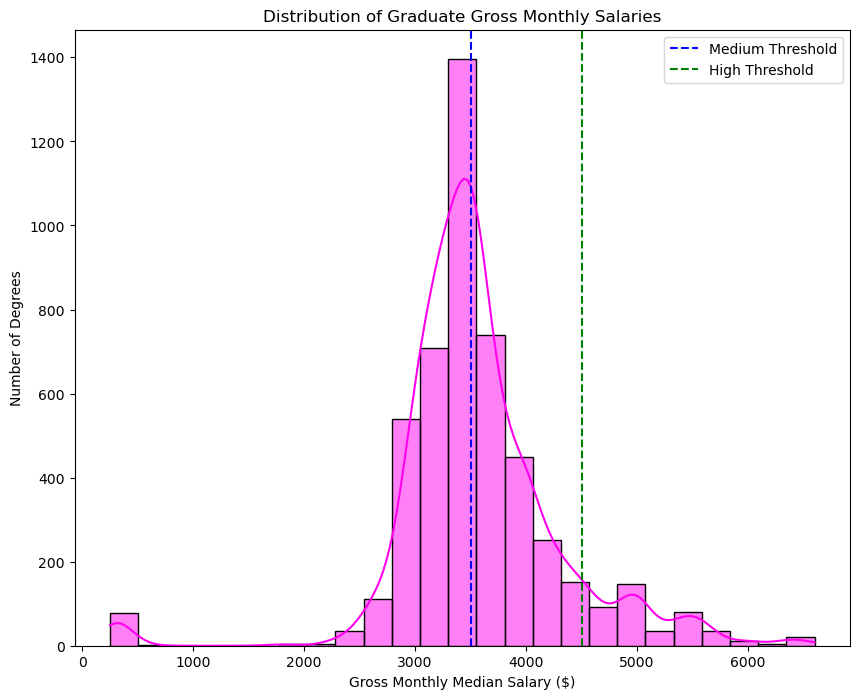

In [472]:
plt.figure(figsize=(10, 8))


sns.histplot(merged_grad['gross_monthly_median'], bins=25, kde=True, color="#FF00EE")
plt.axvline(3500, color='blue', linestyle='--', label='Medium Threshold')
plt.axvline(4500, color='green', linestyle='--', label='High Threshold')
plt.legend()
plt.title('Distribution of Graduate Gross Monthly Salaries')
plt.xlabel('Gross Monthly Median Salary ($)')
plt.ylabel('Number of Degrees')


plt.show()


### **Key Insights:**

- Graduate salaries are **`concentrated`** between **`$3,000`** and **`$4,000`**, indicating that most degrees offer moderate earning potential.

- The salary distribution is **`approximately normal`**, with **`most values`** concentrated around the **`$3300 - $3700`** range, indicating a typical graduate earning benchmark, hence explaining the **`tall peak`** around that range, giving the KDE plot a **`bell-shaped`** curve. 
    - However, a **`slight right skew`** can be observed due to a **`small number`** of **`high-paying roles`** extending **`beyond $5000`**, although these do not dominate the overall distribution.

- A few **`low-salary outliers`** appear **`below $1,000`**, indicating potential special cases or reporting anomalies.

- The natural clustering around $3,500–$4,000 supports the chosen salary band thresholds used for categorising salary levels.

## **Visual Representation 2: Boxplot**
- This boxplot compares the gross monthly salary by the top 15 schools.
- It aims to display the distribution of the gross monthly salary per school.

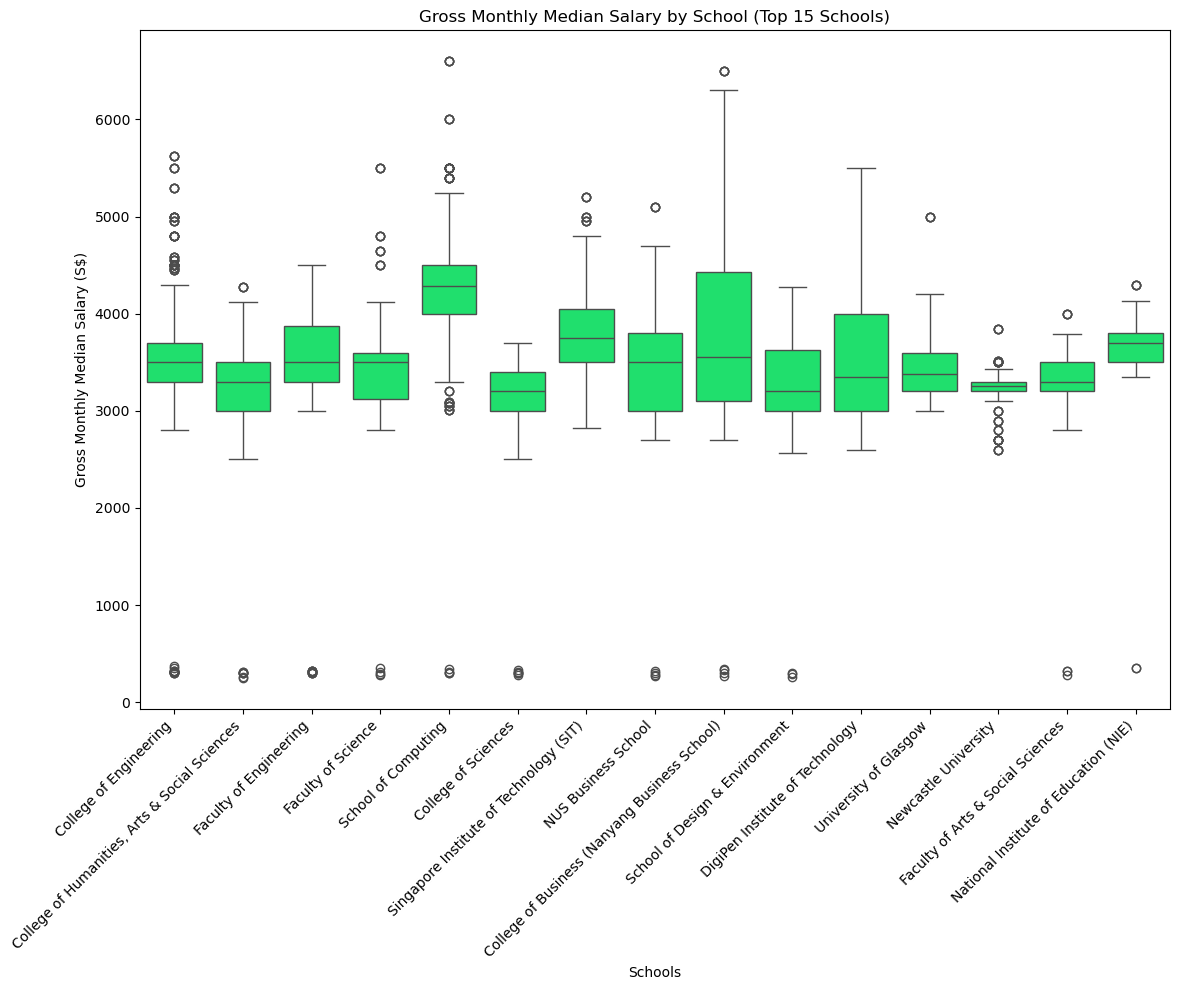

In [473]:
top_n = 15
top_schools = merged_grad['school'].value_counts().head(top_n).index

df_top = merged_grad[merged_grad['school'].isin(top_schools)]

plt.figure(figsize=(12, 10))
sns.boxplot(data=df_top, x='school', y='gross_monthly_median', order=top_schools, color='#00FF67')

plt.title('Gross Monthly Median Salary by School (Top 15 Schools)')
plt.xlabel('Schools')
plt.ylabel('Gross Monthly Median Salary (S$)')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

## **Visual Representation 3: Line Chart - Employment Rate by Year (University)**
- This line chart compares the employment rate of each university for each year.

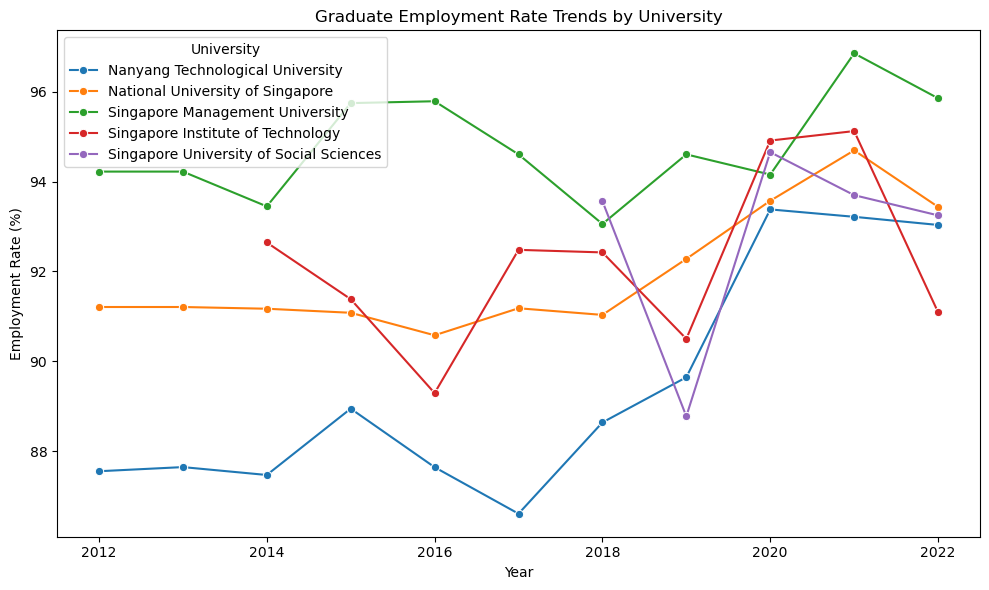

In [474]:
plt.figure(figsize=(10, 6))

sns.lineplot(
    data=merged_grad,
    x='year',
    y='employment_rate_overall',
    hue='university',
    estimator='mean',
    errorbar=None,
    marker='o'
)

plt.title('Graduate Employment Rate Trends by University')
plt.xlabel('Year')
plt.ylabel('Employment Rate (%)')
plt.legend(title='University')
plt.tight_layout()
plt.show()

### **Key Insights:**
- The line chart illustrates year-to-year changes in graduate employment rates across universities, showing that employment outcomes fluctuate rather than remain constant.

- National University of Singapore (NUS) demonstrates the most stable employment trend, with minimal volatility across the years, indicating consistent graduate employability.

- Four universities — Singapore Management University (SMU), Singapore University of Technology and Design (SUTD), Nanyang Technological University (NTU), and NUS — exhibit an overall upward trend in employment rates across the observed period.

- In contrast, Singapore Institute of Technology (SIT) and Singapore University of Social Sciences (SUSS) show a net decline in employment rates, suggesting relatively higher variability and sensitivity to market conditions.

- NTU records the largest overall improvement, increasing from approximately 87–88% in 2012 to around 93% in 2022, reflecting a notable strengthening of graduate employment outcomes over time.

- Several universities experienced a sudden drop in employment rate in 2019, possibly due to the development of the corona virus towards the end of the year. However, there was a clear rebound in 2020 to 2021 which might be due to the work from home environment caused by the nation-wide lockdown. 


---
# **Summary Insights:**
---

## **Graphical Insights:**
- Graduate salaries follow an approximately normal distribution, with most values concentrated around the mid-S$3,000 range, indicating a typical earning benchmark for fresh graduates.

- A small number of high-paying outliers (above S$5,000) and low-salary anomalies (below S$1,000) are present, highlighting unequal earning opportunities and potential special employment cases.

- Salary outcomes vary substantially across schools, with certain institutions showing consistently higher median salaries and wider salary spreads, indicating institutional differences in earning potential.

- Employment rates remain generally high across universities over time, with most institutions maintaining outcomes in the low-to-mid-90% range, suggesting a relatively stable graduate job market.
    - However, noticeable year-to-year fluctuations occur, indicating that graduate employability is dynamic rather than guaranteed.

- Some universities demonstrate stronger long-term resilience, showing stable or improving employment trends, while others exhibit higher volatility and occasional declines, implying differing levels of career security by institution.

- Higher salary outcomes do not consistently align with stronger employment stability, reinforcing that pay alone is not a reliable indicator of long-term job security.



## **Does Our Analysis Answer the Research Question:**
- This dataset successfully answers the salary and stability components of job attractiveness.

- It provides strong evidence on:

    - Typical graduate earning levels

    - Differences in salary across schools and universities

    - Long-term employment stability by institution



## **Practical Takeaways:**
- Do not prioritise salary alone — consider both pay and long-term employment stability.

- Favour institutions and degrees that demonstrate consistent employment outcomes over time, even if salaries are moderate.

- Use salary as a screening factor, but use employment trends as a risk-management factor.

- Combine salary data with qualitative job factors (e.g. work-life balance, job satisfaction, company culture) for a holistic job attractiveness assessment.




---
# **Final Conclusion:**
- Salary outcomes and employment stability vary meaningfully across schools and universities, indicating that institutional choice plays a major role in graduate job prospects. While high salaries are appealing, they do not guarantee stronger job stability, highlighting a trade-off between earning potential and long-term employability. In contrast, universities offering moderate salaries but consistently high employment rates may provide better career security than high-paying but volatile pathways. Overall, job attractiveness should not be measured by salary alone; students should also consider institutional resilience and historical employment trends when making career decisions.


---
